# Optimization in PyTorch — Gradient Descent, SGD, Numerical Stability, and L1 Regularization

**General guidelines for this (and future) hometasks**

* **Do not delete the task formulations**
* Many hometasks will be like "implement something, then perform experiments, then write your conclusions". We're sure many of you will delegate the first and the second step to coding agents, but please do at least the final stage yourself :)
* The plots should be meaningful: a plot must have a name, every curve or point cloud on a plot must be labeled
* Plots supporting comparison should actually enable it. For example, if you compare training loss curves of two models, they should be either on the same plot or side by side, with the same axis scales
* It goes without saying that the takeaways should actually follow from the evidence ;)

**Learning goals of this hometask**

By completing this assignment, you will:
1. Understand preprocessing design choices (tokenization provided, fixed vocabulary).
2. Implement and train Logistic Regression manually in PyTorch using SGD.
3. Explain why numerical stability matters in softmax and log-loss.
4. Understand how optimization parameters like learning rate and batch size affect training.
5. Understand the effect of L1 regularization and why it encourages sparsity.
6. Understanding how an optimization algorithm behaves when the loss function has different shapes.


**The dataset and the task**

For this assignment, we will use the SST-2 dataset (  [The Stanford Sentiment Treebank](https://huggingface.co/datasets/stanfordnlp/sst2).), a binary sentiment classification dataset in which each sentence is labeled as either negative or positive.

We will use linear models for classification, which means that we need a fixed number of numerical features to describe each sentence. For that, we'll perform:

* **Preprocessing** - to make the data a little more well-behaved
* **Tokenization** - splitting the sentences into atomic units - in this case, words
* **Feature creation** - turning bags of words into numerical features - word frequencies. We keep only 10,000 most frequent words, because we can only work with fixed-length feature vectors. You'll see that more "serious" models, such as LLMs, use fixed-length vocabularies too, though we'll learn how to do it without discarding information (by using sub-word and bit-wise tokenization).

Tokenization and preprocessing are already implemented for you in this task, but we want you to understand understand the design choices behind the them, so please check the description below (in the hidden cells).

### Loading and preparing the dataset

We will perform minimal text cleaning:

   * convert all text to lowercase

   * keep letters, numbers, spaces, and basic punctuation

   * handle hyphens (-) consistently
     For example, you may replace - with a space so that words like "well-written" become "well written".


In [2]:
!pip install datasets

In [3]:
from datasets import load_dataset
sst2 = load_dataset("SetFit/sst2")

data_train = sst2['train']
data_val = sst2['validation']

/Users/YOUR_USER/dev/cloud/nebius/lesson4_27_03_assignment/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Repo card metadata block was not found. Setting CardData to empty.


**Text Cleaning**

Before converting text into a numerical representation (e.g., Bag-of-Words), it is important to apply text cleaning.

The goal of this step is to reduce noise and ensure that similar pieces of text are represented consistently.

We use the following cleaning function:

In [4]:
import re

def clean_text(text:str) -> str:
  #lowercase letters only
  text = text.lower()

  #replace hyphens with space
  text = text.replace('-',' ')

  #keep letters,numbers, spaces, and basic punctuations
  text = re.sub(r'[^a-zA-Z0-9\s.,!?]', '', text)

  #collapse multiple spaces
  text = re.sub(r'\s+', ' ', text).strip()

  return text

#apply cleaning
data_train = data_train.map(lambda x: {'clean_text': clean_text(x['text'])})
data_val = data_val.map(lambda x: {'clean_text': clean_text(x['text'])})



In [5]:
from collections import Counter
import random

random.seed(42)

print(f'size of training set: {len(data_train)}')
print(f'size of validation set: {len(data_val)}\n')

for i in range(5):
  r = random.randint(0,len(data_train))
  print(f'{data_train[r]['label_text']} Text: {data_train[r]['clean_text']} ')


train_counts = Counter(data_train["label"])
val_counts = Counter(data_val["label"])

train_total = len(data_train)
val_total = len(data_val)

print("\nTraining set label distribution:")
print(f"Negative (0): {train_counts[0]} ({train_counts[0] / train_total:.2%})")
print(f"Positive (1): {train_counts[1]} ({train_counts[1] / train_total:.2%})")

print("\nValidation set label distribution:")
print(f"Negative (0): {val_counts[0]} ({val_counts[0] / val_total:.2%})")
print(f"Positive (1): {val_counts[1]} ({val_counts[1] / val_total:.2%})")

size of training set: 6920
size of validation set: 872

positive Text: the extent to which it succeeds is impressive . 
positive Text: remarkable for its excellent storytelling , its economical , compressed characterisations and for its profound humanity , it s an adventure story and history lesson all in one . 
positive Text: the unexpected thing is that its dying , in this shower of black and white psychedelia , is quite beautiful . 
negative Text: matrix style massacres erupt throughout ... but the movie has a tougher time balancing its violence with kafka inspired philosophy . 
positive Text: the closest thing to the experience of space travel 

Training set label distribution:
Negative (0): 3310 (47.83%)
Positive (1): 3610 (52.17%)

Validation set label distribution:
Negative (0): 428 (49.08%)
Positive (1): 444 (50.92%)


We convert the text into numerical vectors that can be used as input for machine learning models.

1. Implementing the Bag-of-Words (BoW) representation building a vocabulary using only the training set.

2. Count the frequency of each token across the training corpus.

3. Keep only the top V=10,000 most frequent tokens (or fewer if memory is limited).

4. Convert each sentence into a sparse vector of token counts.

Each vector should represent how many times each vocabulary word appears in the sentence.

For example, if the vocabulary contains: ["movie", "good", "bad"]

Then the sentence: "good movie good"

Should become: [1,2,0]

**Note:** this is a simple bag of word implementation and not standart practice.


In [6]:
def tokenize(text):
  '''Helper function to split the text into words/tokens'''
  return text.split()

def build_vocabulary(data, top_k=10000):
  '''Build a vocabulary from the training data.'''
  token_counter = Counter()
  for text in data['clean_text']:
    tokens = tokenize(text)
    token_counter.update(tokens)
  most_common = token_counter.most_common(top_k)
  vocab = {word: i for i, (word, _) in enumerate(most_common)}
  return vocab

def convert_text_to_vec(text, vocab):
  '''Convert text into a vector of token counts.'''
  tokens = tokenize(text)
  vec = np.zeros(len(vocab), dtype=int)
  for token in tokens:
    if token in vocab:
      vec[vocab[token]] += 1
  return vec

def dataset_to_vec(data,vocab) :
  '''Convert the dataset into a vector of token counts.'''
  vectors = []
  for text in data['clean_text']:
    vec = convert_text_to_vec(text, vocab)
    vectors.append(vec)
  return np.array(vectors)


In [7]:
import numpy as np

# Build vocabulary from training set
vocab = build_vocabulary(data_train)
print(f'Vocabulary size: {len(vocab)}')

# Vectorize training data
train_vectors = dataset_to_vec(data_train, vocab)
print(f'Vectorized training data shape: {train_vectors.shape}')

# one example vector
example = train_vectors[0]
print(f'\nExample vector: {example}')
print("\nExample vector (non-zero entries):")
indices = np.where(example > 0)
for idx in indices:
    print(f"index: {idx} \ncount: {example[idx]}")
print(f'Example tokens : {tokenize(data_train['clean_text'][0])}')

print(f'Length of tokens: {len(tokenize(data_train['clean_text'][0]))}')
print(f'Length of non-zero entries: {len(indices[0])}')

Vocabulary size: 10000
Vectorized training data shape: (6920, 10000)

Example vector: [0 1 1 ... 0 0 0]

Example vector (non-zero entries):
index: [   1    2    3    4    5   66  118  119  361  554  646 1317 1822 4926
 7197 7198] 
count: [1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1]
Example tokens : ['a', 'stirring', ',', 'funny', 'and', 'finally', 'transporting', 're', 'imagining', 'of', 'beauty', 'and', 'the', 'beast', 'and', '1930s', 'horror', 'films']
Length of tokens: 18
Length of non-zero entries: 16


**Our training data for the task 1 will be:**

In [8]:
X_train = train_vectors
y_train = np.array(data_train["label"], dtype=np.float32)
X_val = dataset_to_vec(data_val, vocab)
y_val =  np.array(data_val["label"], dtype=np.float32)


### **Part 1 - Implement SGD for Logistic Regression in PyTorch (70 points)**

#### **Task 1.1 - Binary vs. Softmax Formulation and Numerical Stability of Cross-Entropy Loss (10 points)**



In this task, you will explore two ways to formulate the loss function for a classification problem and understand why numerical stability is important.

**a. Binary formulation**

   In the binary formulation, the model has:

   * a single output
   * sigmoid activation
   * binary cross-entropy loss

   This produces a probability: P(y=1|x)
   
   A prediction is then obtained using a threshold:
   * predict class 1 if p>0.5
   * otherwise predict class 0

   For binary logistic regression, the standard loss function is the **binary cross-entropy loss**:

   $L= -\frac{1}{N}\sum_{i=1}^N[y_ilog(\hat{y_i})+(1-y_i)log(1-\hat{y_i})]$

   where $\hat{y_i}$ is the predicted probability after applying sigmoid.

   Since this loss contains both: $log(\hat{y})$ and $log(1-\hat{y})$ , numerical problems may appear if $\hat{y_i}$ becomes extremely close to 0 or 1.

   A stable implementation should therefore clamp the predicted probabilities:
```
y_pred = # SIGMOID(LOGITS)
epsilon = 1e-15  
y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)
log_loss = # <SMTH FROM y_pred>
```

**Note:** the threshold 0.5 is used only to convert probabilities into class predictions for evaluation.
It must not be used inside the loss function.

**b. Softmax formulation**

  Now, we will reformulate the same problem as a 2-class classification problem using softmax (This formulation is more general and can also be used for more than 2 classes.).
  
  **Step 1 — Convert labels to one-hot encoding**
  
  In our dataset the labels are either 1 or 0 (i.e positive or negetive). To use softmax will require us to convert the labels into a one-hot representation:
  * class 0 ---> [1,0]
  * class 1 ---> [0,1]

  Now our model will output 2 outputs instead of 1 and we will require to apply softmax to get the probability of class 0 vs. class 1.

  **Step 2 - Implementing softmax and log-loss**
  
   This can be implemented in two ways:

  1. **Naive version:**
  
     Given logits z = [$z_1,z_2,...,z_k$]

     softmax($z_i$) = $\frac{\exp(z_i)}{\sum_j\exp(z_j)}$


  2. **Stable version:**

     softmax($z_i$) = $\frac{\exp(z_i-max(z))}{\sum_j\exp(z_j-max(z))}$

   Than the cross entropy loss for the true class y is :

   **L = -log(softmax($z_y$))**

   or equivalently, for one-hot labels:
   
   **$L= -\sum_{c=1}^Ky_clog(\hat{y_c})$**

**Task**

A. Conceptual questions

For both the binary and softmax formulations, explain:

* Why do we need numerical stability? Where can the naive implementation fail?
  - Because if our prediction is very close to 0 or to 1, because of the log computation the loss function can be very close to +-infinity. 
  The software might produces a NaN or Inf (Infinity) and corrupt all the subsequent math.

* Why does the stability transformation not change the final softmax probabilities? 
  - softmax subtracts the the highest score (max(z)) from all the logits before exponanating, this cancels out perfectly — it is subtracted from every term of both numerator and denominator, so it divides out.
The final percentage chances exactly the same

* Why does this transformation improve numerical stability?
  - exp(z) grows extremely fast — for large logits (e.g. z=1000), exp(1000)     
  overflows to inf on any computer. By subtracting max(z), the largest value fed into exp becomes 0, so exp(0) = 1 is the ceiling. All other terms are ≤ 1, keeping everything in a safe numerical range. 

B. Implementation
1. Implement a binary cross-entropy loss function for the binary formulation.
2. Make sure your implementation is numerically stable.




In [9]:
def binary_cross_entropy_loss(y_pred, y_true):
    """
    Compute the binary cross-entropy loss for a logistic regression model.
    """
    epsilon = 1e-15

    # Clamp predictions away from 0 and 1 to avoid log(0) = -inf
    # Without this, a confident wrong prediction causes infinite loss
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)

    # Binary cross-entropy: -mean( y*log(p) + (1-y)*log(1-p) )
    # .mean() gives a single scalar — required for .backward() to work
    # When loss.backward() is called, Autograd traverses the computation graph backward 
    # from the loss tensor to the input tensors that were involved in its calculation and 
    # had requires_grad=True. It applies the chain rule of calculus 
    # to compute the gradient of the loss with respect to each of these relevant tensors.
    # grad Attribute: The computed gradients are then accumulated in the .grad attribute
    #  of the respective tensors
    # These gradients are then used by an optimizer (e.g., SGD, Adam) to update the model's
    # parameters in the direction that minimizes the loss
    loss = -(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred)).mean()

    return loss

# --- Quick sanity check ---
# Perfect prediction (p=1 for y=1): loss should be ~0
# Wrong prediction (p=0 for y=1): loss should be large (but not inf due to clamping)
import torch
y_pred_test = torch.tensor([0.9, 0.1, 0.8, 0.0])  # last one is the dangerous case
y_true_test = torch.tensor([1.0, 0.0, 1.0, 1.0])
print("Loss:", binary_cross_entropy_loss(y_pred_test, y_true_test).item())
# Without clamping, log(0.0) = -inf and the loss would be nan/inf


Loss: 8.743160247802734


####**Task 1.2. - Implement Logistic Regression in PyTorch (10 points)**



In this task, you will implement a logistic regression model from scratch using PyTorch primitives.

The logistic regression prediction function is:

$\hat{Y} = \frac{1}{1+exp^{-(wx +b)}}$

Complete the class below.

You are required to implement:

1. weight initialization (with different options)
2. the forward pass (logits + sigmoid)
3. prediction logic (thresholding)

In [10]:
import torch
import torch.nn as nn

class LogisticRegression(nn.Module):

    def __init__(self, n_features, init="zeros"):
        """
        Parameters
        ----------
        n_features : int
            Number of input features

        init : str or torch.Tensor
            Initialization method for weights:
            - "zeros"  -> initialize weights to zeros
            - "random" -> small random values (recommended scale ~0.01)
            - torch.Tensor -> use provided tensor
        """

        super().__init__()

        # TODO:
        # Initialize the weight vector `w` based on the `init` argument
        # Make sure:
        # - shape is (n_features, 1)
        # - random initialization uses SMALL values (important!)
        # - if init is a tensor, clone + detach it

        # x is (batch, featurs) putting 1 in w to get (batch,1) output
        if init == "zeros":
            w = torch.zeros((n_features, 1))

        # small sigomoid is flattest(good gradients, large but not saturated) near 0.
        elif init == "random":
            # the 1 in randn means, mean ± 3*std = 0 ± 3*1 = -3 to 3  
            w = torch.randn((n_features, 1)) * 0.01

        elif isinstance(init, torch.Tensor):
            # .clone() — make a copy so we do not share memory with the caller's tensor
            # .detach() — remove from any existing computation graph (clean slate for training)
            # .reshape() — ensure correct shape
            w = init.clone().detach().reshape(n_features, 1)

        else:
            raise ValueError("init must be 'zeros', 'random', or a torch.Tensor")

        # TODO:
        # Wrap weights and bias using nn.Parameter
        self.w = nn.Parameter(w)
        # Always initialize bias to zero — no reason to randomize it
        # nn.Parameter tells PyTorch to track this for gradient updates
        self.b = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        """
        Forward pass

        Steps:
        1. Compute logits: x @ w + b
        2. Apply sigmoid to get probabilities

        Returns
        -------
        probs : torch.Tensor
            Values in range [0, 1]
        """

        # TODO:                                                                                       
        #logit = w[0]*count("great") + w[1]*count("terrible") + ...                                                     
        #A high positive logit → sigmoid pushes toward 1 (positive review).                   
        #A high negative logit → sigmoid pushes toward 0 (negative review)."""  
        logits = x @ self.w + self.b
        probs = torch.sigmoid(logits)

        return probs

    def predict(self, x):
        """
        Convert probabilities to class predictions

        Rule:
        - class 1 if p >= 0.5
        - class 0 otherwise
        """

        # TODO:
        probs = self.forward(x)
        preds = (probs >= 0.5).float()

        return preds

####**Task 1.3 - Train Logistic Regression with SGD Using Your Previous Implementations (10 point)**



In this task, you will train the logistic regression model you implemented earlier using mini-batch stochastic gradient descent (SGD).

You must use:

1. your LogisticRegression class from Task 1.2
2. your binary_cross_entropy_loss function from Task 1.1

The goal of this task is to practice building a full training loop in PyTorch while keeping the model and loss implementations modular.

Your function should
1. Initialize a LogisticRegression model
2. Train it on the training set using mini-batch SGD
3. Record the training log-loss after each epoch
4. Compute and report evaluation metrics on both the training and validation sets after each epoch.
You may choose any evaluation metric you find appropriate, such as accuracy, precision, recall, or F1-score, but you must briefly explain why this metric is suitable for this task.

- i chose accuracy since SST-2 is roughly 50/50 balanced. When classes are balanced, accuracy is a fair and interpretable metric — it directly tells you what fraction of predictions are correct. if data was imbalance we could choose F1.
5. Save the model parameters w and b after each batch update into a history log
6. Return:
   * the final trained parameters w and b
   * the batch-wise history of w and b


Bellow is a suggested skeleton you may revised



In [11]:
import torch
import json
import os

def sgd_logistic_regression(
    X_train, y_train,
    X_val, y_val,
    lr=0.01,
    epochs=20,
    batch_size=100,
    init="zeros",
    penalty='none',          # For Task 1.5 : options: 'none', 'l1', 'l2'
    reg_lambda=0.0,          # For Task 1.5
    metric='accuracy',
    print_metrics=False
):
    """
    Train a logistic regression model using mini-batch SGD.

    You must use:
    - LogisticRegression
    - binary_cross_entropy_loss

    Parameters
    ----------
    X_train, y_train : training data
    X_val, y_val     : validation data
    lr : float
        Learning rate
    epochs : int
        Number of passes over the training data
    batch_size : int
        Mini-batch size
    init : str
        Weight initialization passed to LogisticRegression
    penalty : str
        'none', 'l1', or 'l2'
    reg_lambda : float
        Regularization strength
    metric : str
        Evaluation metric to report ('accuracy' , 'f1' or other)
    print_metrics : bool
        Whether to print metrics after each epoch

    Returns
    -------
    w : numpy.ndarray
        Final learned weights
    b : numpy.ndarray
        Final learned bias
    history : list
        Batch-wise history of parameter values
    epoch_log : list
        Per-epoch logs (loss + metrics)
    """


    # 1. Convert data to tensors
    # PyTorch works with tensors (like numpy arrays but with GPU support and autograd)
    # .view(-1, 1) reshapes from [N] to [N, 1] so matrix math works correctly

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

    n_samples, n_features = X_train_tensor.shape


    # 2. Initialize model
    # This creates our logistic regression with weights and bias from Task 1.2

    model = LogisticRegression(n_features=n_features, init=init)


    # 3. Create optimizer
    # SGD = Stochastic Gradient Descent
    # It will update model.w and model.b using gradients computed by .backward()
    # lr controls step size: too small = slow, too large = overshoots

    optimizer = torch.optim.SGD(model.parameters(), lr=lr)


    # 4. Create logs

    history = []      # save w, b after each batch update
    epoch_log = []    # save epoch-level loss and metrics


    # 5. Training loop
    # Each epoch = one full pass through ALL training data
    # Within each epoch, we process data in mini-batches

    # epoch is iteration on all batches where in each batch we calculate loss and update the params according to   
    # the loss function.   

    for epoch in range(epochs):

        # Shuffle training data at the beginning of each epoch
        # WHY? Without shuffling, the model sees the same sequence of batches every epoch.
        # This can cause it to "memorize" the order rather than learn general patterns.
        # torch.randperm(N) returns a random permutation of [0, 1, ..., N-1]
        perm = torch.randperm(n_samples)
        X_train_epoch = X_train_tensor[perm]
        y_train_epoch = y_train_tensor[perm]

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            # Select mini-batch — a small subset of training data
            # WHY mini-batches? Using ALL data per step (full GD) is slow.
            # Using 1 sample (pure SGD) is noisy. Mini-batch is the sweet spot.
            X_batch = X_train_epoch[start:end]
            y_batch = y_train_epoch[start:end]

            # Forward pass: feed data through model to get predictions
            # model(X_batch) calls LogisticRegression.forward() -> returns probabilities
            y_pred = model(X_batch)

            # Compute non-regularized BCE loss using our function from Task 1.1
            # This measures how far our predictions are from the true labels
            data_loss = binary_cross_entropy_loss(y_pred, y_batch)

            # Task 1.5: Add regularization if needed
            # Regularization penalizes large weights to prevent overfitting
            # penalty == 'l1'  -> reg_lambda * ||w||_1  (encourages sparsity)
            # penalty == 'l2'  -> reg_lambda * ||w||_2^2 (encourages small weights)
            # penalty == 'none' -> no regularization
            if penalty == 'l1':
                reg_term = reg_lambda * torch.sum(torch.abs(model.w))
            elif penalty == 'l2':
                reg_term = reg_lambda * torch.sum(model.w ** 2)
            else:
                reg_term = 0.0

            loss = data_loss + reg_term

            # === The 3-step SGD update ===
            # Step 1: Zero out old gradients (PyTorch accumulates by default)
            optimizer.zero_grad()
            # Step 2: Compute gradients via backpropagation (chain rule)
            #         This fills .grad for every parameter
            loss.backward()
            # Step 3: Update parameters: w = w - lr * w.grad
            optimizer.step()

            # Save current parameter values after the batch update
            # .detach() = remove from computation graph
            # .clone()  = make a copy (otherwise all entries point to same tensor!)
            history.append({
                'epoch': epoch,
                'batch_start': start,
                'w': model.w.detach().clone(),
                'b': model.b.detach().clone()
            })


        # 6. Epoch-level evaluation
        # torch.no_grad() disables gradient tracking — we're just measuring, not training
        # This saves memory and computation

        #now we calculse the final accuracy for the this epoch after all batches. just measuring.                 
        with torch.no_grad():

            # Compute probabilities on full train/val sets
            y_pred_train = model(X_train_tensor)
            y_pred_val = model(X_val_tensor)

            # Compute NON-regularized train loss and val loss
            # We use non-regularized loss to fairly compare across different reg settings
            train_loss = binary_cross_entropy_loss(y_pred_train, y_train_tensor)
            val_loss = binary_cross_entropy_loss(y_pred_val, y_val_tensor)

            # Convert probabilities to binary predictions (0 or 1)
            # Threshold at 0.5: if model says >50% chance positive -> predict positive
            y_hat_train = (y_pred_train >= 0.5).float()
            y_hat_val = (y_pred_val >= 0.5).float()

            # Compute evaluation metric
            if metric == 'f1':
                # F1 = 2 * precision * recall / (precision + recall)
                # Precision = "of predicted positives, how many are correct?"
                # Recall = "of actual positives, how many did we find?"
                # 1e-8 prevents division by zero
                tp_train = (y_hat_train * y_train_tensor).sum().item()
                fp_train = (y_hat_train * (1 - y_train_tensor)).sum().item()
                fn_train = ((1 - y_hat_train) * y_train_tensor).sum().item()
                precision_train = tp_train / (tp_train + fp_train + 1e-8)
                recall_train = tp_train / (tp_train + fn_train + 1e-8)
                train_metric = 2 * precision_train * recall_train / (precision_train + recall_train + 1e-8)

                tp_val = (y_hat_val * y_val_tensor).sum().item()
                fp_val = (y_hat_val * (1 - y_val_tensor)).sum().item()
                fn_val = ((1 - y_hat_val) * y_val_tensor).sum().item()
                precision_val = tp_val / (tp_val + fp_val + 1e-8)
                recall_val = tp_val / (tp_val + fn_val + 1e-8)
                val_metric = 2 * precision_val * recall_val / (precision_val + recall_val + 1e-8)
            else:
                # Accuracy = fraction of correct predictions
                # Simple and fair for balanced datasets like SST-2
                train_metric = (y_hat_train == y_train_tensor).float().mean().item()
                val_metric = (y_hat_val == y_val_tensor).float().mean().item()

        epoch_log.append({
            'epoch': epoch,
            'train_loss': train_loss.item(),
            'val_loss': val_loss.item(),
            'train_metric': train_metric,
            'val_metric': val_metric
        })

        if print_metrics:
            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {train_loss.item():.4f} | "
                f"Val Loss: {val_loss.item():.4f} | "
                f"Train {metric}: {train_metric:.4f} | "
                f"Val {metric}: {val_metric:.4f}"
            )

    # Save epoch_log to logs/ folder as JSON for Task 1.4 analysis
    os.makedirs('logs', exist_ok=True)
    log_filename = f'logs/lr{lr}_bs{batch_size}_init{init}_pen{penalty}.json'
    with open(log_filename, 'w') as f:
        json.dump(epoch_log, f, indent=2)
    print(f"\nEpoch log saved to {log_filename}")

    return model.w.detach().numpy(), model.b.detach().numpy(), history, epoch_log

####**Task 1.4 - Experiments (20 points)**




Run multiple experiments with different combinations of:
* learning rates - [0.01, 0.03, 0.1 , 0.3 , 1.0]
* batch sizes - [50, 100 , 200]

For each experiment, record the final train and validation evaluation metric and the log-loss.

**Visualization:**

Present your results using a heatmap, where:
* X-axis: learning rate
* Y-axis: batch size
* Values: evaluation metric (train / validation)


**Analysis:**

Explain (in text) how learning rate and batch size affect:
- convergence speed
- stability of training
- final performance

Support your explanation using the patterns observed in your heatmap.


Epoch 1/20 | Train Loss: 0.6842 | Val Loss: 0.6838 | Train accuracy: 0.5490 | Val accuracy: 0.5470
Epoch 2/20 | Train Loss: 0.6786 | Val Loss: 0.6775 | Train accuracy: 0.5971 | Val accuracy: 0.6193
Epoch 3/20 | Train Loss: 0.6738 | Val Loss: 0.6722 | Train accuracy: 0.6163 | Val accuracy: 0.6548
Epoch 4/20 | Train Loss: 0.6696 | Val Loss: 0.6677 | Train accuracy: 0.6160 | Val accuracy: 0.6560
Epoch 5/20 | Train Loss: 0.6658 | Val Loss: 0.6635 | Train accuracy: 0.6270 | Val accuracy: 0.6571
Epoch 6/20 | Train Loss: 0.6623 | Val Loss: 0.6598 | Train accuracy: 0.6316 | Val accuracy: 0.6606
Epoch 7/20 | Train Loss: 0.6591 | Val Loss: 0.6564 | Train accuracy: 0.6367 | Val accuracy: 0.6606
Epoch 8/20 | Train Loss: 0.6561 | Val Loss: 0.6534 | Train accuracy: 0.6416 | Val accuracy: 0.6697
Epoch 9/20 | Train Loss: 0.6533 | Val Loss: 0.6505 | Train accuracy: 0.6461 | Val accuracy: 0.6720
Epoch 10/20 | Train Loss: 0.6506 | Val Loss: 0.6478 | Train accuracy: 0.6501 | Val accuracy: 0.6766
Epoch 11/

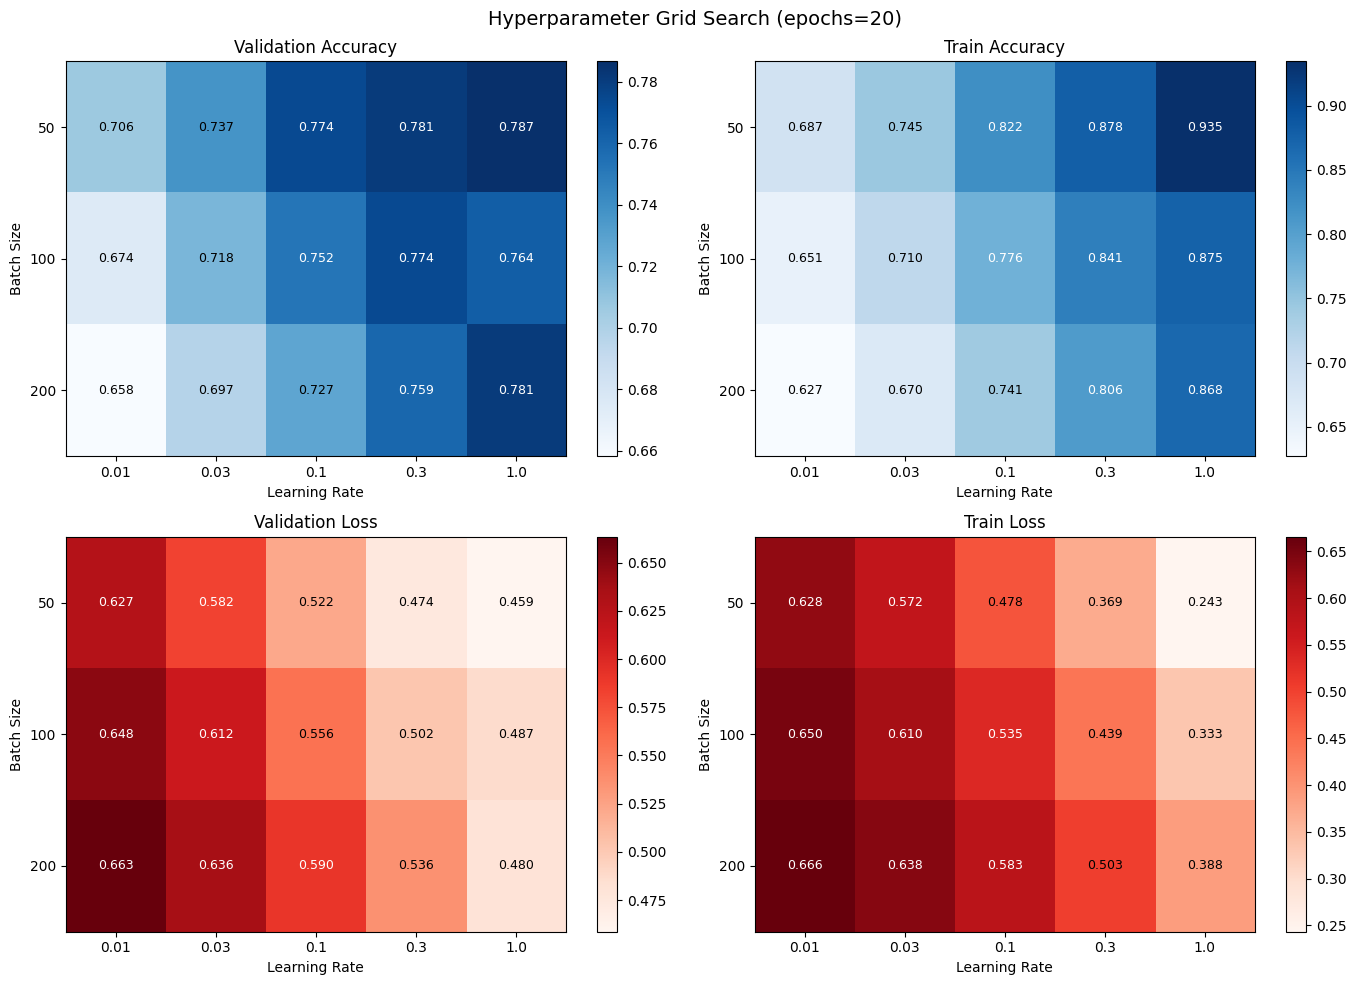

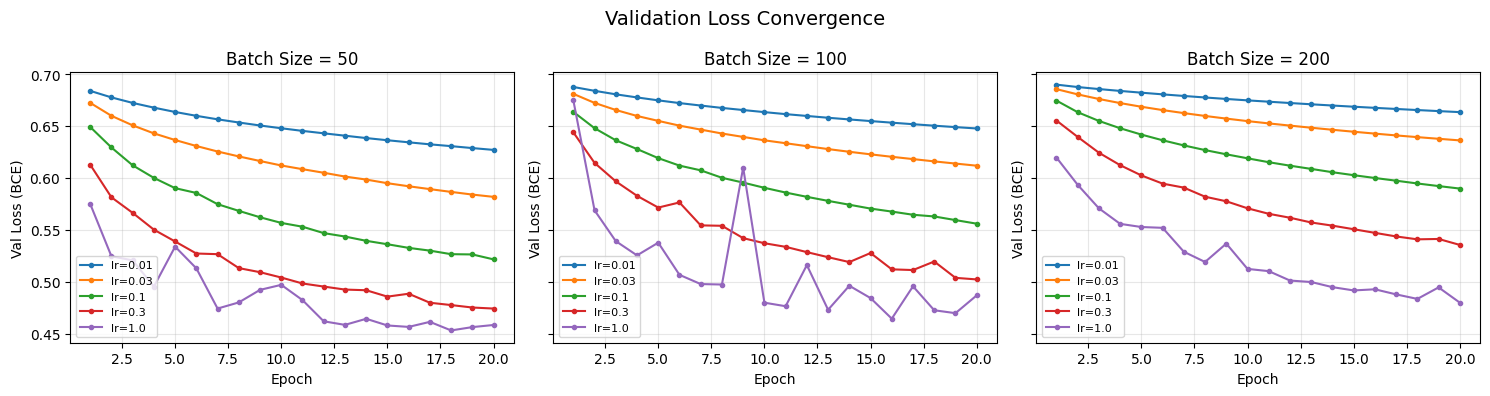

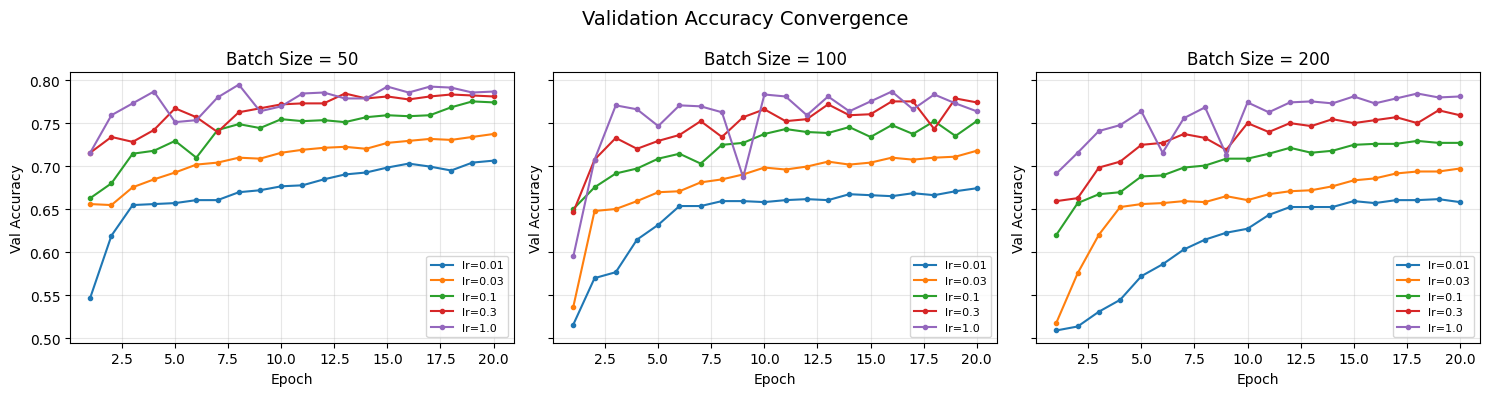

In [12]:
learning_rates = [0.01, 0.03, 0.1, 0.3, 1.0]
batch_sizes = [50, 100, 200] 

# Run all combinations, collect results
results = {}
for bs in batch_sizes:
    for lr in learning_rates:
        w, b, history, epoch_log = sgd_logistic_regression(
            X_train, y_train, X_val, y_val,
            lr=lr, epochs=20, batch_size=bs,
            init="zeros", print_metrics=True
        )
        results[(lr, bs)] = epoch_log
        # Save epoch_log to logs/
        with open(f'logs/lr{lr}_bs{bs}.json', 'w') as f:
            json.dump(epoch_log, f)

#Heat maps
import numpy as np
import matplotlib.pyplot as plt

# Build 2D grids from results
# Each grid: rows = batch sizes, cols = learning rates
# We pull the LAST epoch's values — that's the final performance after training

val_accuracy_grid = np.zeros((len(batch_sizes), len(learning_rates)))
train_accuracy_grid = np.zeros((len(batch_sizes), len(learning_rates)))
val_loss_grid = np.zeros((len(batch_sizes), len(learning_rates)))
train_loss_grid = np.zeros((len(batch_sizes), len(learning_rates)))

for i, bs in enumerate(batch_sizes):
      for j, lr in enumerate(learning_rates):
          final = results[(lr, bs)][-1]          # last epoch dict
          val_accuracy_grid[i, j] = final['val_metric']
          train_accuracy_grid[i, j] = final['train_metric']
          val_loss_grid[i, j] = final['val_loss']
          train_loss_grid[i, j] = final['train_loss']

# Plot 2x2 heatmaps
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hyperparameter Grid Search (epochs=20)', fontsize=14)

grids = [
    (val_accuracy_grid,   'Validation Accuracy', 'Blues'),
    (train_accuracy_grid, 'Train Accuracy',      'Blues'),
    (val_loss_grid,  'Validation Loss',     'Reds'),
    (train_loss_grid,'Train Loss',          'Reds'),
]

for ax, (grid, title, cmap) in zip(axes.flat, grids):
    im = ax.imshow(grid, cmap=cmap, aspect='auto')

    # Label axes with actual hyperparameter values
    ax.set_xticks(range(len(learning_rates)))
    ax.set_xticklabels([str(lr) for lr in learning_rates])
    ax.set_yticks(range(len(batch_sizes)))
    ax.set_yticklabels([str(bs) for bs in batch_sizes])
    ax.set_xlabel('Learning Rate')
    ax.set_ylabel('Batch Size')
    ax.set_title(title)

    # Write the number inside each cell so you can read exact values
    for ii in range(len(batch_sizes)):
        for jj in range(len(learning_rates)):
            ax.text(jj, ii, f'{grid[ii, jj]:.3f}',
                    ha='center', va='center', fontsize=9,
                    color='white' if grid[ii, jj] > grid.mean() else 'black')

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('logs/heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Convergence curves: Val Loss over epochs ──
# One subplot per batch size, one curve per learning rate
# Steep drop = fast convergence, jagged = unstable training

epochs = 20

fig, axes = plt.subplots(1, len(batch_sizes), figsize=(5 * len(batch_sizes), 4), sharey=True)
fig.suptitle('Validation Loss Convergence', fontsize=14)

for ax, bs in zip(axes, batch_sizes):
    for lr in learning_rates:
        losses = [e['val_loss'] for e in results[(lr, bs)]]
        ax.plot(range(1, epochs + 1), losses, label=f'lr={lr}', marker='o', markersize=3)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Val Loss (BCE)')
    ax.set_title(f'Batch Size = {bs}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('logs/convergence_val_loss.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Convergence curves: Val Accuracy over epochs ──

fig, axes = plt.subplots(1, len(batch_sizes), figsize=(5 * len(batch_sizes), 4), sharey=True)
fig.suptitle('Validation Accuracy Convergence', fontsize=14)

for ax, bs in zip(axes, batch_sizes):
    for lr in learning_rates:
        accs = [e['val_metric'] for e in results[(lr, bs)]]
        ax.plot(range(1, epochs + 1), accs, label=f'lr={lr}', marker='o', markersize=3)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Val Accuracy')
    ax.set_title(f'Batch Size = {bs}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('logs/convergence_val_acc.png', dpi=150, bbox_inches='tight')
plt.show()

#### Analysis: How Learning Rate and Batch Size Affect Training

**Metric choice:** We use accuracy because SST-2 is roughly balanced (~50/50 positive/negative). When classes are balanced, accuracy fairly reflects model performance.

**1. Convergence Speed**

From the heatmaps: low learning rates (0.01, 0.03) show significantly worse final accuracy — they haven't converged in 20 epochs.

From the convergence curves: lr=1.0 drops to low loss within 2-3 epochs, while lr=0.01 is still slowly declining at epoch 20. Smaller batch sizes also converge faster — with batch_size=50 (~1,340 updates/epoch) vs batch_size=200 (~335 updates/epoch), more updates per epoch means faster learning.

**2. Stability**

From the convergence curves: lr=1.0 shows jagged, spiky loss curves (especially with batch_size=100) — the model overshoots the optimum, corrects, then overshoots again. lr=0.01 is perfectly smooth but too slow. lr=0.1 and 0.3 offer a good balance of speed and stability.

Smaller batches also add noise — each mini-batch is a less representative sample of the full data, so gradient estimates are noisier.

**3. Final Performance**

From the heatmaps: the best val accuracy is 0.787 (lr=1.0, batch_size=50) — roughly 4 out of 5 reviews classified correctly. However, lr=1.0 is the most unstable. A practical choice would be **lr=0.3, batch_size=50**: nearly as good accuracy with much more stable training.

0.787 is reasonable for a simple bag-of-words logistic regression. The model is linear — it learns individual word associations but can't understand word combinations (e.g., "not bad" = positive, but the model sees "not" and "bad" separately).

**4. The Train-Val Gap**

From the heatmaps: train accuracy reaches ~0.935 while val accuracy is ~0.787 — a gap of ~15%. The model fits training data better than it generalizes to new data. The gap is larger at high learning rates. We still need to address this gap.

####**Task 1.5 — L1 Regularization and Sparsity (20 points)**



In this task, you will extend your implementation from Task 1.2 (SGD training) to include **L1 regularization**, and study how it affects the model.

**What is Regularization/ Penalty**

When there are too many features, some features might not be so important at all, but if we keep it, and try to fit our model to it perfectly, then it might overfit, trying to capture noisy (irrelevant) data or patterns. To reduce this overfitting so the model generalizes well and remove noisy data we use **regularization**. In linear models, mostly these regularization techniques are used:

* **L1 Penalty**: adding $\lambda *\sum{|w_i|}$ to the loss function

* **L2 Penalty**: adding $\lambda *\sum{||w||_i^2}$ to the loss function


**Why is this important?**

L1 *sparsifies* data, with part of weights being pushed strongly towards zero (with the right optimization technique, these weights become almost zero).
This leads to implicit feature selection.

In contrast, L2 shrinks weights but rarely makes them exactly zero.

**Task**

1. Modify your `sgd_logistic_regression` function from Task 1 to include L1 penalty.

2. Compare weight initialization:
   
   Try initializing the weight vector w in two different ways:
   * All zeros
   * Small random values
   
   Compare:
    * Stability (does training diverge? NaNs?)
    * Final performance
    * Sparsity (how many weights go to zero, use a small tolerance like 1e-7). Note that you'll unlikely get zeros. You'd need special optimization methods such as *proximal descent* to get true feature elimination; with SGD you'll still make part of the weights really small, so you'll still observe the pattern.
   
3. Study the effect of $\lambda$
   
   Run experiments with:

          reg_lambda = [0,1e-4,1e-3,1e-2,1e-1]
    
     Keep other parameters fixed (recommended):
     
      *  lr = 0.1
      *  batch_size = 100
     
     For each λ, record:
      * Train metric (for example accuracy or F1)
      * Validation metric
      * Number of non-zero weights that exceed a small threshold such as 1e-7

4. Visualization
     
     Plot:
       
     * number of non-zero weights vs lambda
     * train metric vs lambda
     * for a subset of features that get eliminated by the l1 regularization, training dynamics of their weights (weight vs step)

5. Write a small paragraph summarizing your insights

In [ ]:
# <Your code here>

### **Part 2 - Comparing Optimization Algorithms on a Simple vs. Difficult Function (30 points)**


In this task, you will implement and compare several optimization algorithms on two different mathematical functions.

An optimization algorithm is a method used to update the model's parameters (weights and bias) in order to minimize the loss function.

At each step, it uses the gradients (how the loss changes) to decide:
- in which direction to move
- and how big the update should be

Different optimizers (like SGD, Adam) differ in how they use the gradients and how they control the step size, which affects how fast and how stably the model learns.

The purpose of this task is to help you build intuition for how optimization behaves in:

1. a simple convex function

2. a function with a narrow curved valley

You will implement the following optimizers:

* Gradient Descent (GD)
* Momentum
* AdaGrad
* Adam

Use your optimizers on the following functions:

Function A — Convex bowl:

$f(x,y)= x^2 +4y^2$

This is a simple convex function with a single global minimum.

Function B — the Six-hump Camel function:

$$
\left(4-2.1x^2+\frac{x^4}{3}\right)x^2+xy+\left(-4+4y^2\right)y^2.
$$

This function is much harder to optimize. It has two global minima: $(0.0898, -0.7126)$ and $(-0.0898,0.7126)$, with value about $-1.0316$ - and also several local minina.

Start from at least one non-optimal initial point, for example: (-2, -1.5)


**Task**

For each optimizer and for each function:

1. Initialize the parameters (x,y)
2. repeatedly compute the gradient
3. Update the parameters according to the optimizer rule
4. Record:
  * the function value at each iteration
  * the parameter values $(x_t,y_t)$ at each iteration

**Goal**

Compare how the different optimizers behave on:

* a simple convex function
* a difficult non-convex function

In particular, observe:

* how quickly each optimizer converges
* whether the optimization path is smooth or oscillatory
* whether an optimizer that works well on the convex bowl also works well on Camel
* how the geometry of the function affects the optimization process

**Coding**

Fill in the gaps in the implementation of the optimization method. By the way, you might find this code very repetitive. Can you find a way of shrinking it and getting rid of repetitions?

**Visualization**

Create the following plots:
1. Function value vs. iteration number
2. Optimization trajectories in the (x,y) plane. Use the `plot_trajectories_camel_log` function or create your own function to make an animation/gif.

For each question, please plot the behaviour of all optimization methods on one plot so that you could compare them.

**Analysis**

Summarize your findings in 2-3 text paragraphs. Things to ponder:

* Which optimizer performs best on the convex bowl?
* Which optimizer performs best on the Camel function? Will any of them reliably find global optima or will all of them get trapped in local minina from time to time, depending on the starting point.
* Do the same hyperparameters work equally well for both functions?
* What advantages do Momentum, AdaGrad, and Adam provide compared to plain Gradient Descent?

In [ ]:
import torch
import matplotlib.pyplot as plt

# Convex bowl
def bowl(theta):
    x, y = theta[0], theta[1]
    return x**2 + 2*y**2


# camel
def camel(theta):
    x, y = theta[0], theta[1]
    return (4 - 2.1 * x**2+ x**4 / 3) * x**2 + x * y + (-4 + 4 * y**2) * y**2


def plot_trajectories_camel_log(f, results, xlim=(-3, 3), ylim=(-2, 2), title="Optimization Trajectories"):
    x_values = np.linspace(xlim[0], xlim[1], 400)
    y_values = np.linspace(ylim[0], ylim[1], 400)
    X, Y = np.meshgrid(x_values, y_values)

    grid = np.stack((X, Y), axis=-1)
    Z = f(torch.tensor(grid, dtype=torch.float32)).detach().numpy()

    plt.figure(figsize=(8, 6))
    plt.contour(X, Y, np.log1p(Z), levels=30)

    for name, (trajectory, _) in results.items():
        plt.plot(trajectory[:, 0], trajectory[:, 1], marker='o', markersize=2, label=name)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def gradient_descent(f, theta0, lr=0.001, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        # TODO: compute loss
        loss = ...

        # TODO: compute gradients
        ...

        # TODO: update parameters
        with torch.no_grad():
            theta -= ...

        # reset gradients
        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def momentum(f, theta0, lr=0.001, beta=0.9, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = ...
        ...

        with torch.no_grad():
            # TODO: update velocity
            v = ...

            # TODO: update parameters
            theta -= ...

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adagrad(f, theta0, lr=0.1, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    G = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = ...
        ...

        with torch.no_grad():
            # TODO: accumulate squared gradients
            G = ...

            # TODO: update parameters
            theta -= ...

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adam(f, theta0, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    m = torch.zeros_like(theta)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(1, n_steps + 1):
        loss = ...
        ...

        with torch.no_grad():
            # TODO: update moments
            m = ...
            v = ...

            # TODO: bias correction
            m_hat = ...
            v_hat = ...

            # TODO: update parameters
            theta -= ...

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

#Run experiments

theta0 = torch.tensor([-1.5, 1.5])

results_bowl = {
    "GD": gradient_descent(bowl, theta0, lr=...),
    "Momentum": momentum(bowl, theta0, lr=..., beta=...),
    "AdaGrad": adagrad(bowl, theta0, lr=...),
    "Adam": adam(bowl, theta0, lr=...)
}

results_camel = {
    "GD": gradient_descent(camel, theta0, lr=...),
    "Momentum": momentum(camel, theta0, lr=..., beta=...),
    "AdaGrad": adagrad(camel, theta0, lr=...),
    "Adam": adam(camel, theta0, lr=...)
}

### **Knowledge Bonus.** An attempt at explaining the L1 regularization phenomenon + a bit about proximal descent



The antigradient of the regularized loss $\mathcal{L}_{reg}(w) = \mathcal{L}(w) + \lambda\|w\|_1$ is
$$-\nabla_w\mathcal{L}_{reg}(w) = -\nabla_w\mathcal{L}(w) - \lambda\cdot \mathrm{sign}(w),$$
where $\mathrm{sgn}$ is the elementwise sign. This means that during the gradient descent the $i$-th coordinate of $w$ changes as
$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w) + \begin{cases}
-\alpha\lambda,\mbox{ if $w_i > 0$},\\
+\alpha\lambda,\mbox{ if $w_i < 0$},
\end{cases},$$
where $\alpha$ is the step size. In other words, the rightmost summand pushes our $w_i$ towards $0$ with force $\alpha\lambda$. Now, imagine that the $i$-th feature is not very important. In this case, most likely, $\frac{\partial}{\partial w_i}\mathcal{L}(w)$ is small (change in $w_i$ doesn't change the loss much). So, the dominant force is the $\pm\alpha\lambda$, which may explain the almost-linear trajectories.

Of course, since $\alpha\lambda$ is constant and doesn't depend on $w_i$. This prevents us from converging to zero and explains the final noisy behaviour of $w_i$. We just leap around the origin.

I'd like to add here that if we used proximal descent, the step would become a two-step procedure like this:

$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w),\\
w_i\mapsto\begin{cases}
w_i - \alpha\lambda,\mbox{ if $w_i \geqslant \alpha\lambda$},\\
0,\mbox{ if $|w_i| > \alpha\lambda$},\\
w_i + \alpha\lambda,\mbox{ if $w_i \leqslant -\alpha\lambda$},\\
\end{cases}$$
This way, small values of $w_i$ will be automatically zeroed, and they will only be able to escape zero again if the gradient push them hard enough.

**Comparison with L2 regularization**. For L2 regularization, the gradient step for the $i$-th coordinate would be
$$w_i \mapsto w_i - \alpha\frac{\partial}{\partial w_i}\mathcal{L}(w) - 2\alpha\lambda w_i$$
The rightmost term here depends on $w_i$; the closer it is to zero, the less influential it is, and the more important $\alpha\frac{\partial}{\partial w_i}\mathcal{L}(w)$ becomes. However, if the $i$-th feature is so worthless that $\alpha\frac{\partial}{\partial w_i}\mathcal{L}(w)\approx 0$, the process
$$w_i \mapsto w_i -  2\alpha\lambda w_i$$
converges to zero in contrast with the leaping behaviour of
$$w_i\mapsto w_i \pm\alpha\lambda$$